In [3]:
#MEMUAT PUSTAKA DAN DATASET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Memuat dataset California Housing bawaan sklearn
housing = fetch_california_housing(as_frame=True)
df_a = housing.frame

print("Bentuk Data (Baris, Kolom):", df_a.shape)
df_a.head()

Bentuk Data (Baris, Kolom): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        0.692308     32.54000

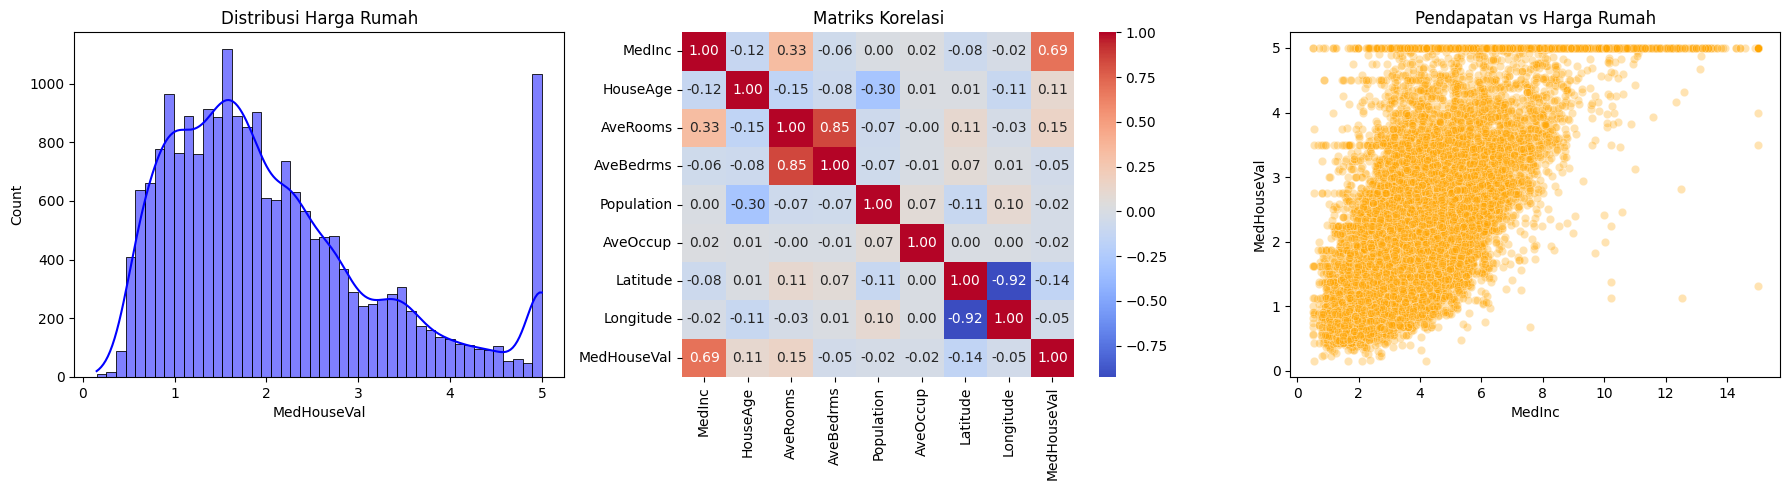

In [4]:
#EKSPLORASI DAN VISUALISASI DATA

# Menampilkan statistik dasar
print(df_a.describe())

# Membuat 3 Grafik Eksplorasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik 1: Sebaran Harga Rumah
sns.histplot(df_a['MedHouseVal'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribusi Harga Rumah')

# Grafik 2: Hubungan Korelasi Antarfitur
sns.heatmap(df_a.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Matriks Korelasi')

# Grafik 3: Pendapatan vs Harga Rumah
sns.scatterplot(x='MedInc', y='MedHouseVal', data=df_a, alpha=0.3, ax=axes[2], color='orange')
axes[2].set_title('Pendapatan vs Harga Rumah')

plt.tight_layout()
plt.show()

In [5]:
#PREPROCESSING DAN PEMILIHAN FITUR

# 1. Cek data hilang dan duplikat
print("Nilai Hilang:", df_a.isnull().sum().sum())
print("Data Duplikat:", df_a.duplicated().sum())

# 2. Pemilihan Fitur: Membuang kolom 'AveBedrms' karena sangat mirip fungsinya dengan 'AveRooms'
X_a = df_a.drop(columns=['MedHouseVal', 'AveBedrms']) # Fitur penentu
y_a = df_a['MedHouseVal']                             # Target harga

Nilai Hilang: 0
Data Duplikat: 0


In [9]:
#PEMBAGIAN DATA DAN STADARISASI SKALA

# Membagi 80% data latih dan 20% data uji
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y_a, test_size=0.2, random_state=42
)

# Menyetarakan skala angka (Scaling)
scaler_a = StandardScaler()
X_train_a_scaled = scaler_a.fit_transform(X_train_a)
X_test_a_scaled = scaler_a.transform(X_test_a)

In [10]:
#PELATIHAN MODEL DAN EVALUASI

# Melatih Model Regresi Linier
model_a = LinearRegression()
model_a.fit(X_train_a_scaled, y_train_a)

# Membuat Prediksi pada Data Uji
y_pred_a = model_a.predict(X_test_a_scaled)

# Menghitung Metrik Evaluasi
mae = mean_absolute_error(y_test_a, y_pred_a)
rmse = np.sqrt(mean_squared_error(y_test_a, y_pred_a))
r2 = r2_score(y_test_a, y_pred_a)

print(f"Rata-rata Kesalahan Mutlak (MAE) : {mae:.4f}")
print(f"Akar Rata-rata Kuadrat Error (RMSE): {rmse:.4f}")
print(f"Skor Akurasi R-squared           : {r2:.4f}")

Rata-rata Kesalahan Mutlak (MAE) : 0.5425
Akar Rata-rata Kuadrat Error (RMSE): 0.7398
Skor Akurasi R-squared           : 0.5823
